# Healthcare Data Analytics – Cleaned Data Inspection

## 1. Load and Validate Cleaned Dataset

In [1]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Locate the project folder
possible_roots = [Path.cwd(), Path.cwd().parent]

project_root = next(
    (p for p in possible_roots
     if (p / "data" / "processed" / "diabetic_data_cleaned.csv").exists()),
    None
)

if project_root is None:
    raise FileNotFoundError(
        "Could not find diabetic_data_cleaned.csv in data/processed"
    )

# Load the cleaned dataset
file_path = (
    project_root / "data" / "processed" /
    "diabetic_data_cleaned.csv"
)

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (101766, 53)


,encounter_id,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,...,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted,total_prior_visits,medication_count,medication_change_flag,diabetes_medication_flag
0,2278392,8222157,Caucasian,Female,[0-10),6,25,1,1,Not Recorded,...,No,No,No,No,No,NO,0,0,0,0
1,149190,55629189,Caucasian,Female,[10-20),1,1,7,3,Not Recorded,...,No,No,No,Ch,Yes,>30,0,0,1,1
2,64410,86047875,AfricanAmerican,Female,[20-30),1,1,7,2,Not Recorded,...,No,No,No,No,Yes,NO,3,0,0,1
3,500364,82442376,Caucasian,Male,[30-40),1,1,7,2,Not Recorded,...,No,No,No,Ch,Yes,NO,0,0,1,1
4,16680,42519267,Caucasian,Male,[40-50),1,1,7,1,Not Recorded,...,No,No,No,Ch,Yes,NO,0,0,1,1


## 2. Dataset Validation

In [2]:

# Check dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Check missing values
print("\nTotal missing values:", df.isna().sum().sum())

# Check completely duplicated records
print("Duplicate rows:", df.duplicated().sum())

# Check unique encounters and patients
print("Unique encounters:", df["encounter_id"].nunique())
print("Unique patients:", df["patient_nbr"].nunique())

# Check the new engineered features
engineered_features = [
    "total_prior_visits",
    "medication_count",
    "medication_change_flag",
    "diabetes_medication_flag"
]

display(df[engineered_features].describe())


Rows: 101766
Columns: 53

Total missing values: 0
Duplicate rows: 0
Unique encounters: 101766
Unique patients: 71518


,total_prior_visits,medication_count,medication_change_flag,diabetes_medication_flag
count,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.202759,0.141314,0.461952,0.770031
std,2.291781,0.356296,0.498553,0.420815
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,1.000000
50%,0.000000,0.000000,0.000000,1.000000
75%,2.000000,0.000000,1.000000,1.000000
max,80.000000,3.000000,1.000000,1.000000


## 3. Readmission Distribution

In [3]:
# Count each readmission category
readmission_counts = df["readmitted"].value_counts()

display(readmission_counts)

# Calculate percentages
readmission_percentage = (
    df["readmitted"].value_counts(normalize=True) * 100
).round(2)

display(readmission_percentage)

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

readmitted
NO     53.91
>30    34.93
<30    11.16
Name: proportion, dtype: float64

In [4]:
print("Total columns:", len(df.columns))
display(pd.DataFrame({
    "Column_Name": df.columns,
    "Data_Type": df.dtypes.astype(str).values
}))

Total columns: 53


,Column_Name,Data_Type
0,encounter_id,int64
1,patient_nbr,int64
2,race,str
3,gender,str
4,age,str
5,admission_type_id,int64
6,discharge_disposition_id,int64
7,admission_source_id,int64
8,time_in_hospital,int64
9,payer_code,str


## 4. Exploratory Data Analysis

### 4.1 Patient Demographics

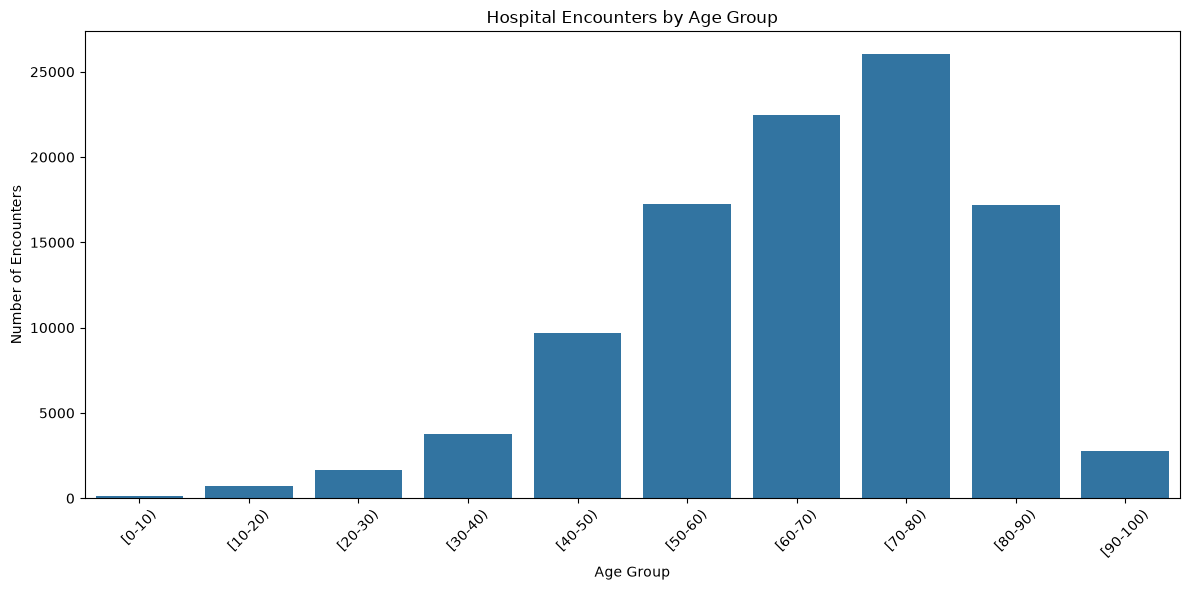

In [5]:
#A. Age distribution

age_order = [
    "[0-10)", "[10-20)", "[20-30)", "[30-40)",
    "[40-50)", "[50-60)", "[60-70)", "[70-80)",
    "[80-90)", "[90-100)"
]

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="age",
    order=age_order
)

plt.title("Hospital Encounters by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Encounters")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64


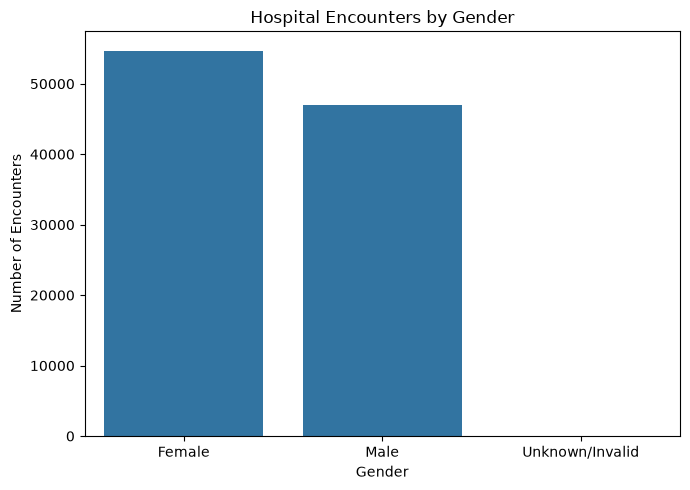

In [6]:
# B. Gender distribution
gender_counts = df["gender"].value_counts()
print(gender_counts)

plt.figure(figsize=(7, 5))

sns.barplot(
    x=gender_counts.index,
    y=gender_counts.values
)

plt.title("Hospital Encounters by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Encounters")
plt.tight_layout()
plt.show()

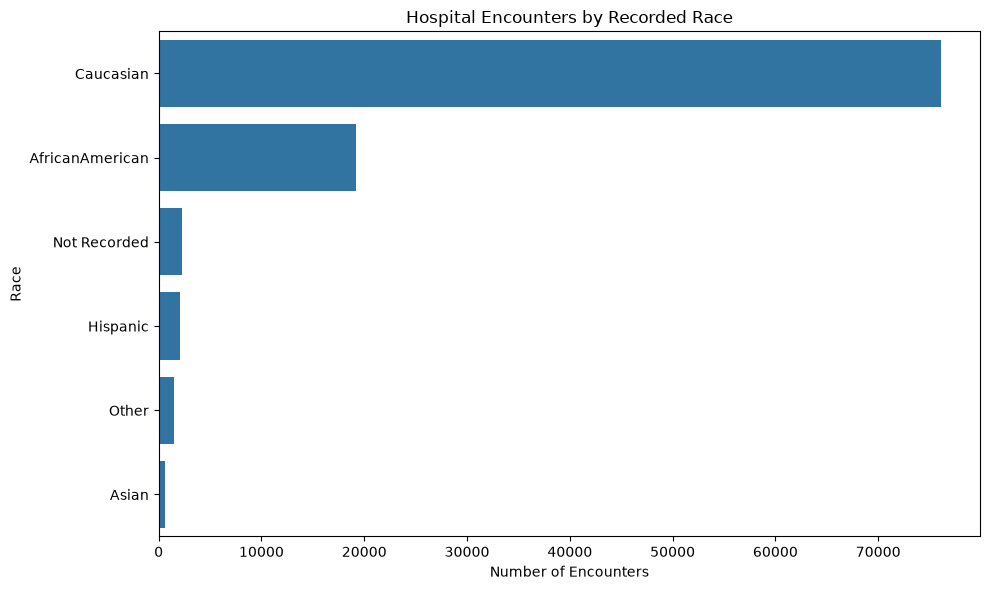

In [7]:
#C. Race distribution
race_counts = df["race"].value_counts()

plt.figure(figsize=(10, 6))

sns.barplot(
    x=race_counts.values,
    y=race_counts.index
)

plt.title("Hospital Encounters by Recorded Race")
plt.xlabel("Number of Encounters")
plt.ylabel("Race")
plt.tight_layout()
plt.show()

## 5. Hospital Activity Analysis

Hospital stay summary:


count    101766.000000
mean          4.395987
std           2.985108
min           1.000000
25%           2.000000
50%           4.000000
75%           6.000000
max          14.000000
Name: time_in_hospital, dtype: float64

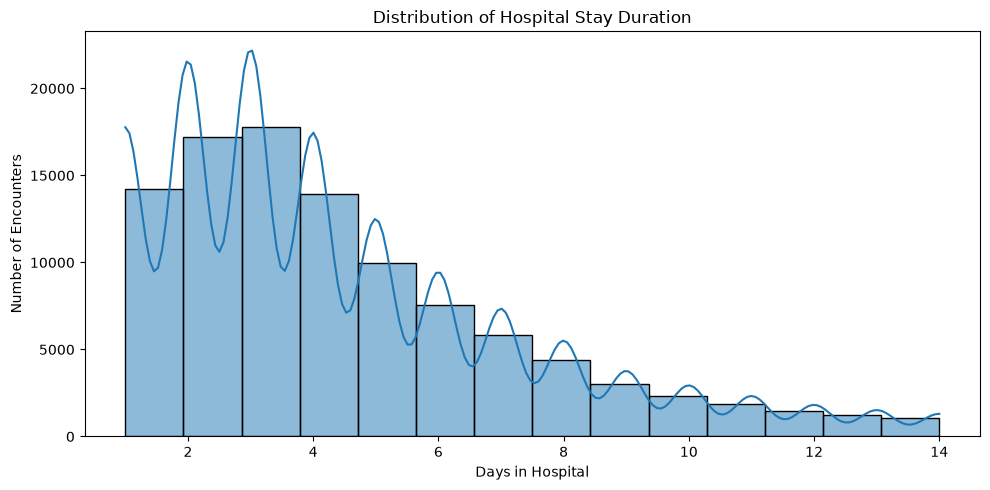

In [8]:
# 5.1 Length of hospital stay
# Convert to numeric
df["time_in_hospital"] = pd.to_numeric(
    df["time_in_hospital"], errors="coerce"
)

# Summary statistics
print("Hospital stay summary:")
display(df["time_in_hospital"].describe())

# Distribution chart
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="time_in_hospital",
    bins=14,
    kde=True
)

plt.title("Distribution of Hospital Stay Duration")
plt.xlabel("Days in Hospital")
plt.ylabel("Number of Encounters")
plt.tight_layout()
plt.show()

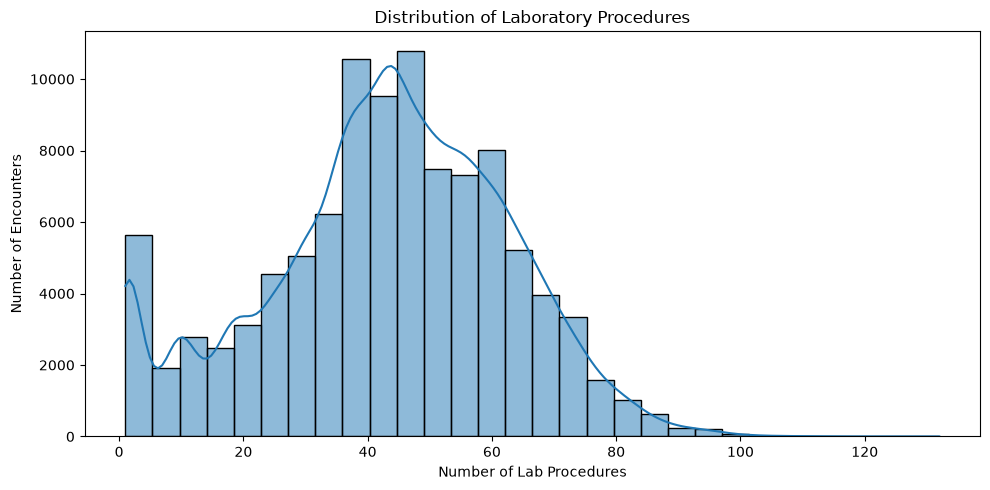

count    101766.000000
mean         43.095641
std          19.674362
min           1.000000
25%          31.000000
50%          44.000000
75%          57.000000
max         132.000000
Name: num_lab_procedures, dtype: float64

In [9]:
# 5.2 Number of laboratory procedures
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="num_lab_procedures",
    bins=30,
    kde=True
)

plt.title("Distribution of Laboratory Procedures")
plt.xlabel("Number of Lab Procedures")
plt.ylabel("Number of Encounters")
plt.tight_layout()
plt.show()

display(df["num_lab_procedures"].describe())

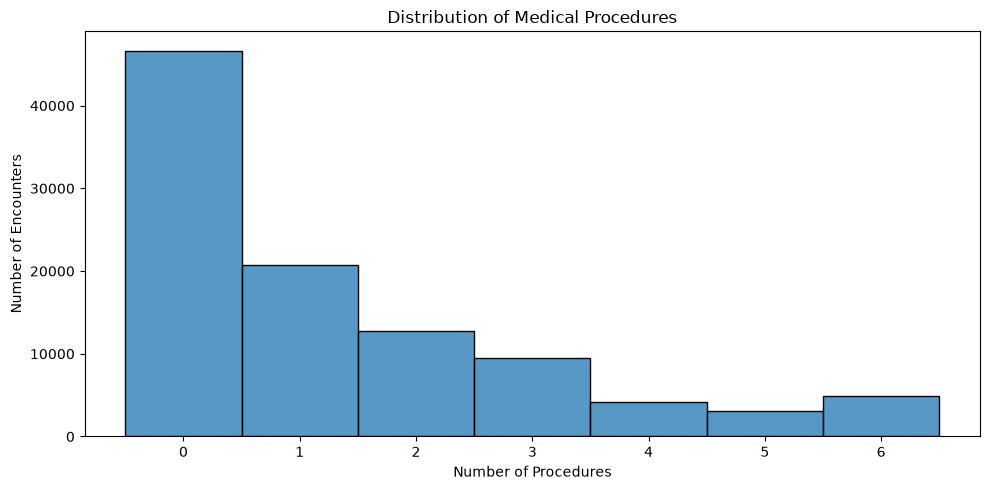

In [10]:
#5.3 Number of medical procedures
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="num_procedures",
    bins=15,
    discrete=True
)

plt.title("Distribution of Medical Procedures")
plt.xlabel("Number of Procedures")
plt.ylabel("Number of Encounters")
plt.tight_layout()
plt.show()

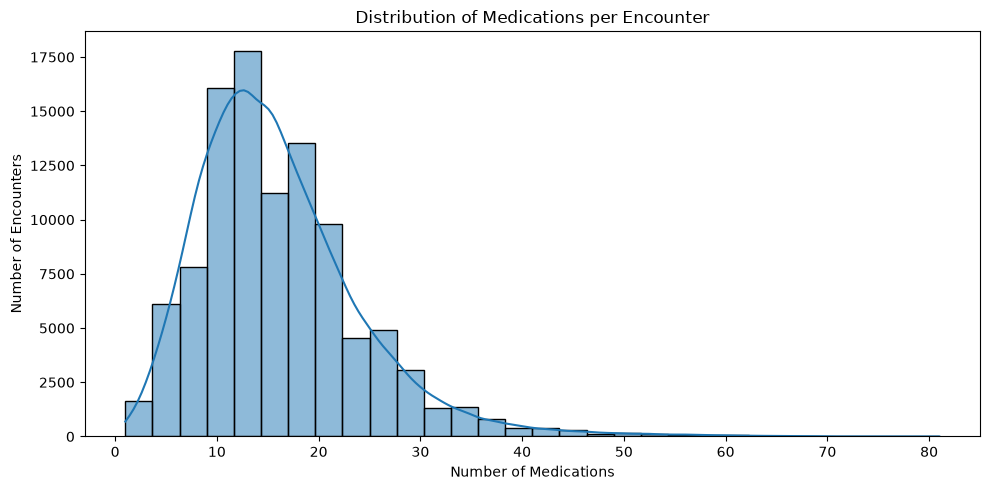

In [11]:
# 5.4 Number of medications
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="num_medications",
    bins=30,
    kde=True
)

plt.title("Distribution of Medications per Encounter")
plt.xlabel("Number of Medications")
plt.ylabel("Number of Encounters")
plt.tight_layout()
plt.show()

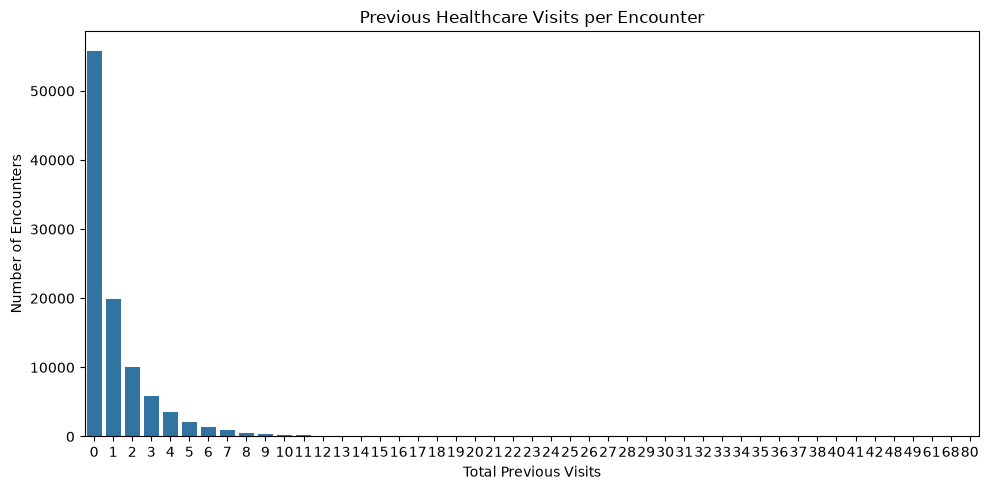

In [12]:
#5.5 Previous hospital visits
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="total_prior_visits"
)

plt.title("Previous Healthcare Visits per Encounter")
plt.xlabel("Total Previous Visits")
plt.ylabel("Number of Encounters")
plt.tight_layout()
plt.show()

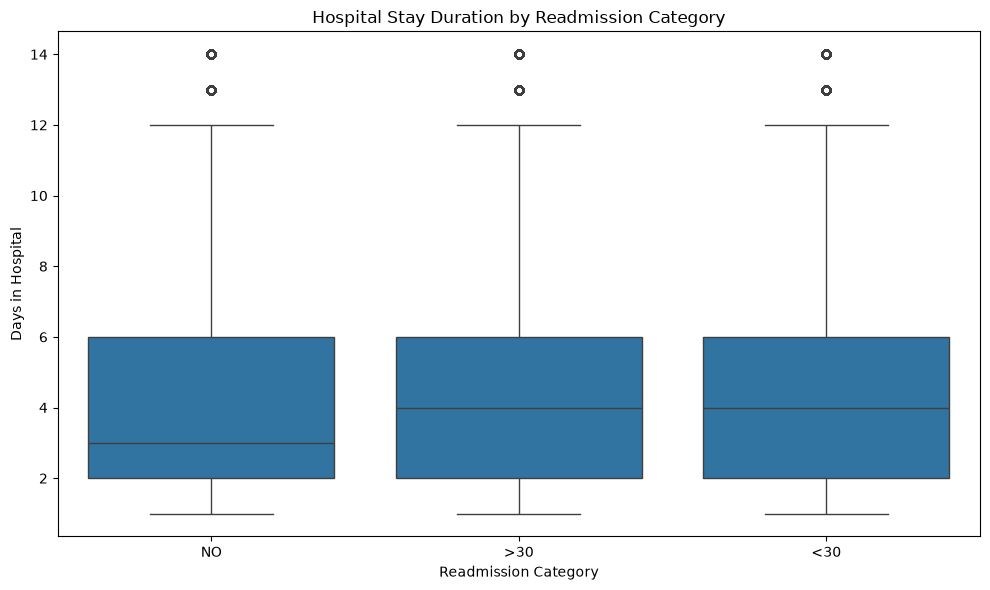

In [13]:
#5.6 Compare hospital stay with readmission
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="readmitted",
    y="time_in_hospital",
    order=["NO", ">30", "<30"]
)

plt.title("Hospital Stay Duration by Readmission Category")
plt.xlabel("Readmission Category")
plt.ylabel("Days in Hospital")
plt.tight_layout()
plt.show()

## 6. Readmission Analysis

### 6.1 Create the readmission target
### 6.2 Overall readmission distribution
### 6.3 Readmission by age group
### 6.4 Readmission by gender and race
### 6.5 Admission type and discharge destination
### 6.6 Previous visits and medication count
### 6.7 Readmission by Medication Count

In [20]:

# 6.1 Create the readmission target
#  Convert readmission into a binary target

df["readmission_30d"] = (
    df["readmitted"].eq("<30").astype(int)
)

print("Readmission target created.")

display(
    df["readmission_30d"].value_counts()
)

display(
    (df["readmission_30d"].value_counts(normalize=True) * 100)
    .round(2)
)


Readmission target created.


readmission_30d
0    90409
1    11357
Name: count, dtype: int64

readmission_30d
0    88.84
1    11.16
Name: proportion, dtype: float64

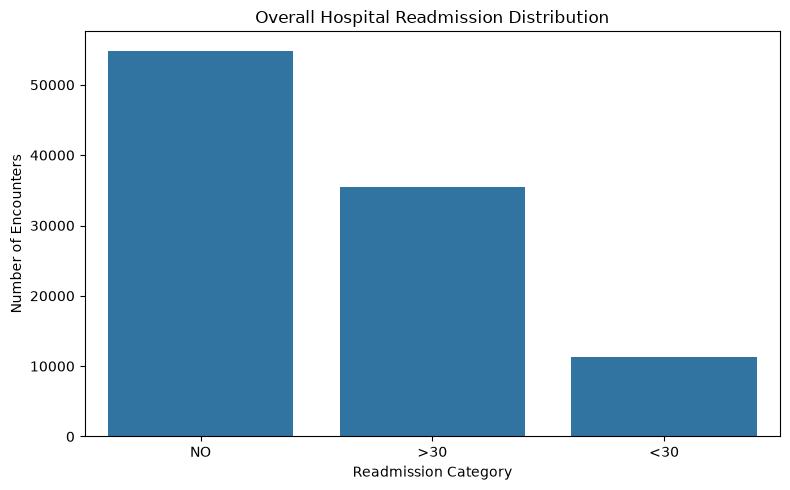

In [21]:
# 6.2 Overall readmission distribution

readmission_counts = df["readmitted"].value_counts()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=readmission_counts.index,
    y=readmission_counts.values
)

plt.title("Overall Hospital Readmission Distribution")
plt.xlabel("Readmission Category")
plt.ylabel("Number of Encounters")
plt.tight_layout()
plt.show()


,age,count,mean,readmission_rate
0,[0-10),161,0.018634,1.863354
1,[10-20),691,0.057887,5.788712
2,[20-30),1657,0.142426,14.242607
3,[30-40),3775,0.112318,11.231788
4,[40-50),9685,0.106040,10.604027
5,[50-60),17256,0.096662,9.666203
6,[60-70),22483,0.111284,11.128408
7,[70-80),26068,0.117731,11.773055
8,[80-90),17197,0.120835,12.083503
9,[90-100),2793,0.110992,11.099177


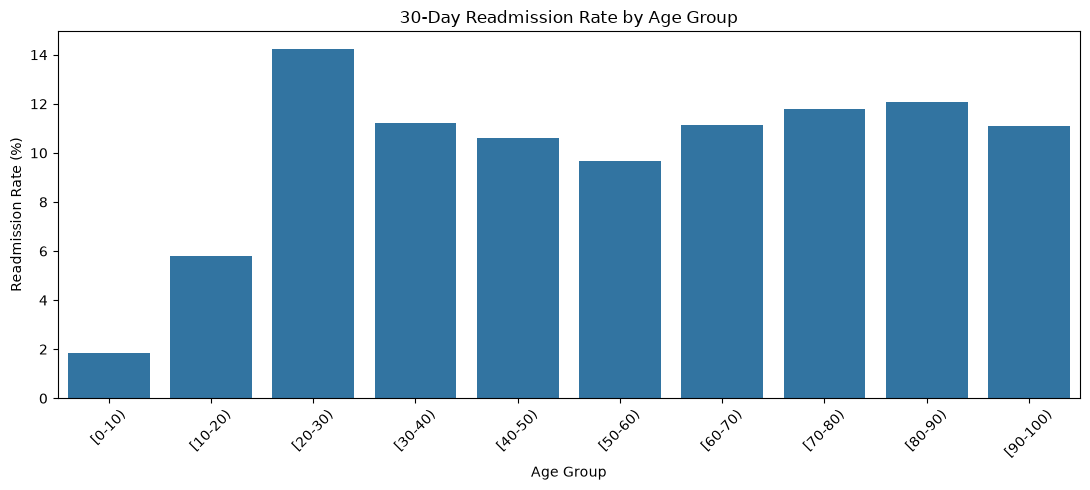

In [22]:
# 6.3 Readmission by age group

age_order = [
    "[0-10)", "[10-20)", "[20-30)", "[30-40)",
    "[40-50)", "[50-60)", "[60-70)", "[70-80)",
    "[80-90)", "[90-100)"
]

age_readmission = (
    df.groupby("age", observed=False)["readmission_30d"]
    .agg(["count", "mean"])
    .reset_index()
)

age_readmission["readmission_rate"] = (
    age_readmission["mean"] * 100
)

age_readmission["age"] = pd.Categorical(
    age_readmission["age"],
    categories=age_order,
    ordered=True
)

age_readmission = age_readmission.sort_values("age")

display(age_readmission)

plt.figure(figsize=(11, 5))

sns.barplot(
    data=age_readmission,
    x="age",
    y="readmission_rate"
)

plt.title("30-Day Readmission Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Readmission Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


,gender,count,mean,readmission_rate
0,Female,54708,0.112452,11.245156
1,Male,47055,0.110615,11.061524
2,Unknown/Invalid,3,0.000000,0.000000


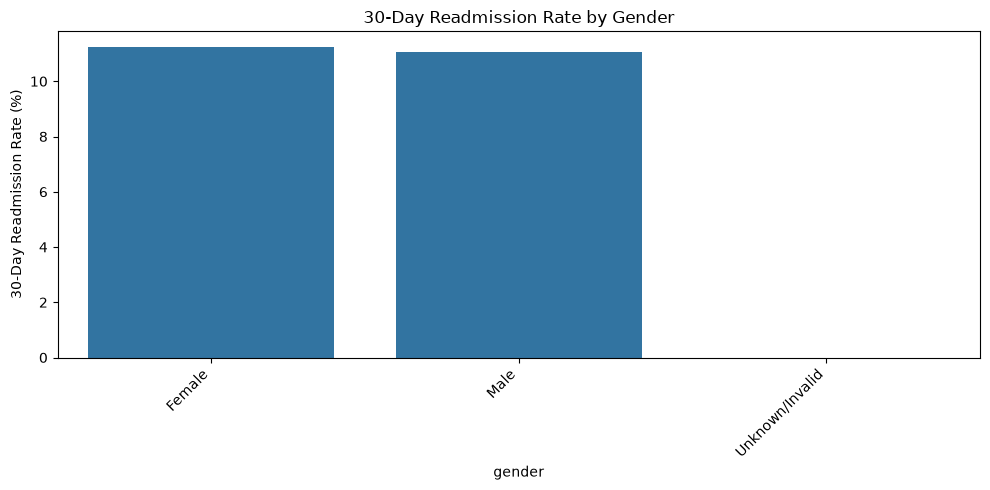

,race,count,mean,readmission_rate
0,AfricanAmerican,19210,0.112181,11.218116
1,Asian,641,0.101404,10.140406
2,Caucasian,76099,0.112906,11.290556
3,Hispanic,2037,0.104075,10.407462
4,Not Recorded,2273,0.082710,8.271007
5,Other,1506,0.096282,9.628154


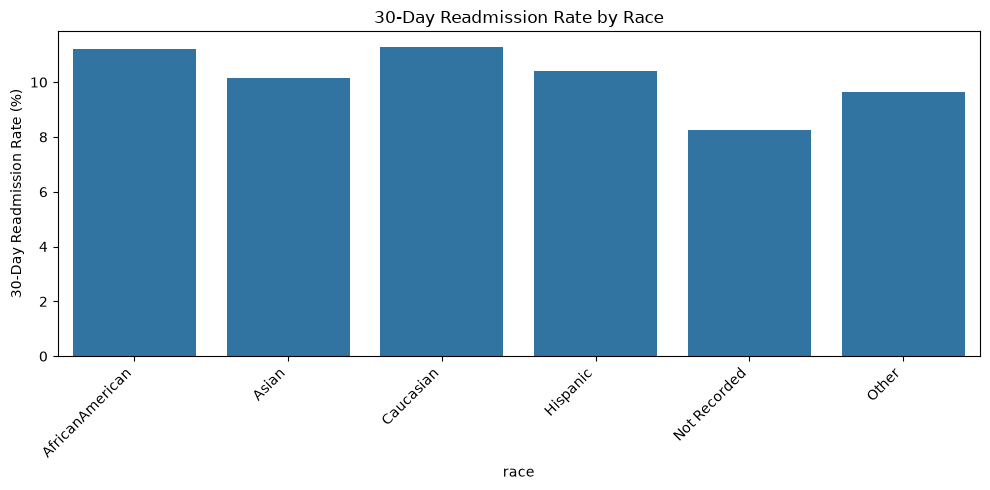

In [23]:
# 6.4 Readmission by gender and race

def plot_readmission_rate(data, column, title, top_n=None):

    summary = (
        data.groupby(column, dropna=False)["readmission_30d"]
        .agg(["count", "mean"])
        .reset_index()
    )

    summary["readmission_rate"] = summary["mean"] * 100

    if top_n is not None:
        summary = summary.nlargest(top_n, "count")

    display(summary)

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=summary,
        x=column,
        y="readmission_rate"
    )

    plt.title(title)
    plt.xlabel(column)
    plt.ylabel("30-Day Readmission Rate (%)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


plot_readmission_rate(
    df,
    "gender",
    "30-Day Readmission Rate by Gender"
)

plot_readmission_rate(
    df,
    "race",
    "30-Day Readmission Rate by Race"
)


,admission_type_id,count,mean,readmission_rate
0,1,53990,0.115225,11.522504
1,2,18480,0.111797,11.179654
2,3,18869,0.103927,10.392708
3,4,10,0.100000,10.000000
4,5,4785,0.103448,10.344828
5,6,5291,0.110754,11.075411
6,7,21,0.000000,0.000000
7,8,320,0.084375,8.437500


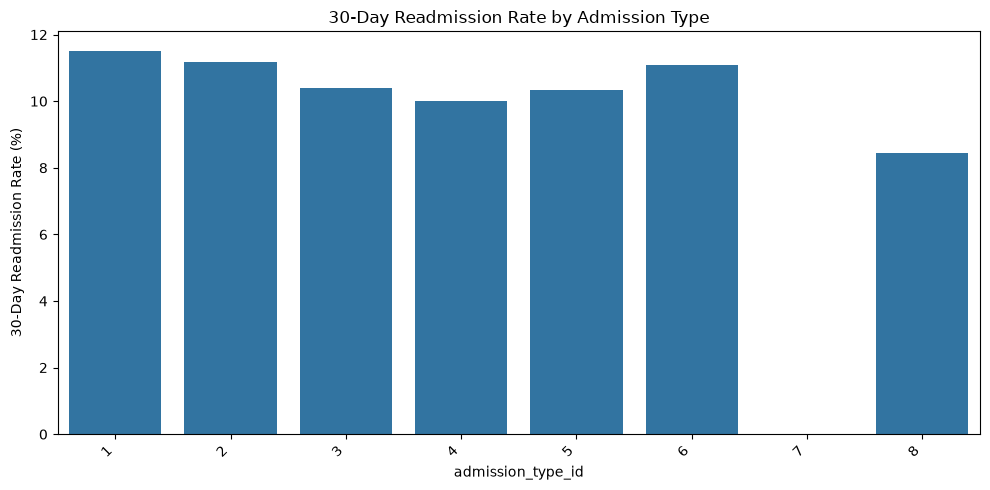

,discharge_disposition_id,count,mean,readmission_rate
0,1,60234,0.093004,9.300395
2,3,13954,0.146625,14.662462
5,6,12902,0.126957,12.695706
17,18,3691,0.124357,12.435654
1,2,2128,0.160714,16.071429
20,22,1993,0.276969,27.696939
10,11,1642,0.000000,0.000000
4,5,1184,0.208615,20.861486
23,25,989,0.093023,9.302326
3,4,815,0.127607,12.760736


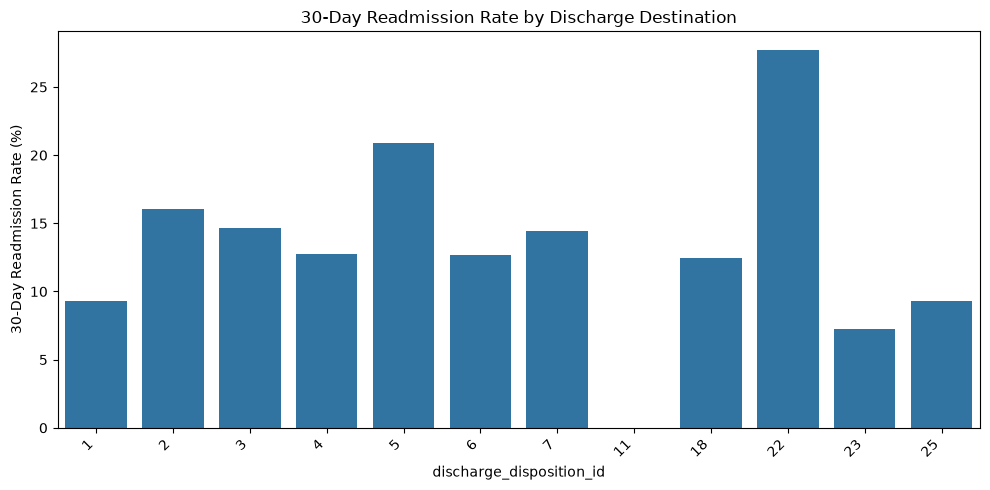

In [24]:
# 6.5 Admission type and discharge destination

plot_readmission_rate(
    df,
    "admission_type_id",
    "30-Day Readmission Rate by Admission Type"
)

plot_readmission_rate(
    df,
    "discharge_disposition_id",
    "30-Day Readmission Rate by Discharge Destination",
    top_n=12
)


,total_prior_visits,count,mean,readmission_rate
0,0,55828,0.081751,8.175109
1,1,19941,0.115641,11.564114
2,2,10062,0.146194,14.619360
3,3,5904,0.152778,15.277778
4,4,3570,0.171148,17.114846
5,5,2036,0.183694,18.369352
6,6,1313,0.232292,23.229246
7,7,868,0.226959,22.695853
8,8,554,0.245487,24.548736
9,9,430,0.274419,27.441860


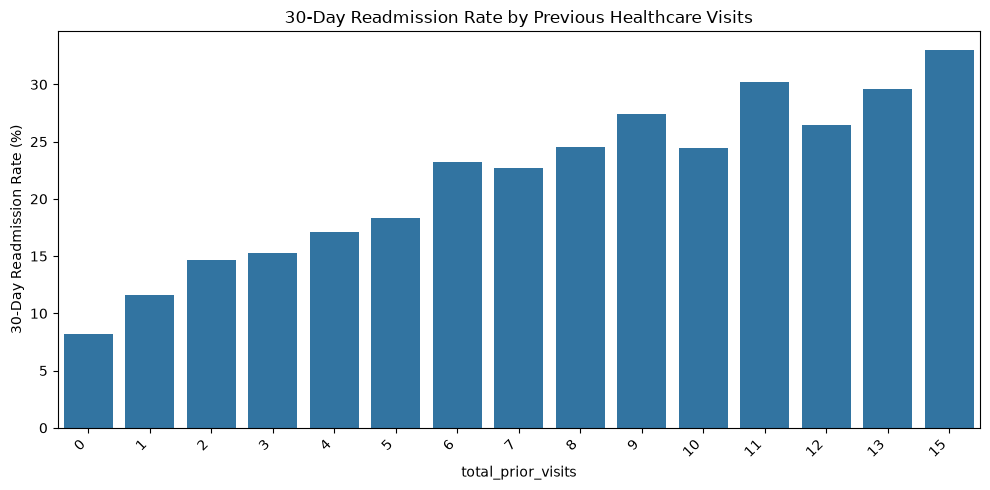

,medication_count,count,mean,readmission_rate
0,0,87665,0.107603,10.760281
1,1,13826,0.136699,13.669897
2,2,270,0.122222,12.222222
3,3,5,0.200000,20.000000


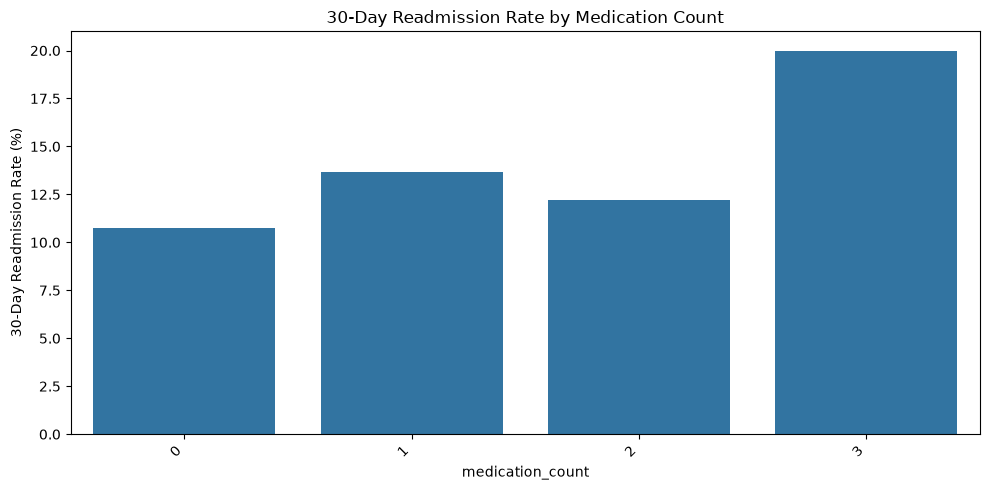

In [25]:
# 6.6 Previous visits and medication count

plot_readmission_rate(
    df,
    "total_prior_visits",
    "30-Day Readmission Rate by Previous Healthcare Visits",
    top_n=15
)

plot_readmission_rate(
    df,
    "medication_count",
    "30-Day Readmission Rate by Medication Count",
    top_n=15
)


## 7. Statistical Analysis

### 7.1 Categorical Variable Association
### 7.2 Numerical Variable Comparison
### 7.3 Statistical Results Interpretation

In [27]:
# 7.1 Chi-square test for categorical variables

from scipy.stats import chi2_contingency

categorical_features = [
    "age",
    "gender",
    "race",
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id"
]

chi_results = []

for column in categorical_features:

    contingency_table = pd.crosstab(
        df[column],
        df["readmission_30d"]
    )

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    n = contingency_table.to_numpy().sum()

    minimum_dimension = min(contingency_table.shape) - 1

    cramers_v = (
        np.sqrt(chi2 / (n * minimum_dimension))
        if minimum_dimension > 0 else np.nan
    )

    chi_results.append({
        "Feature": column,
        "Chi_Square": chi2,
        "P_Value": p_value,
        "Cramers_V": cramers_v
    })

chi_results_df = pd.DataFrame(chi_results)

display(
    chi_results_df.sort_values("P_Value")
)


,Feature,Chi_Square,P_Value,Cramers_V
4,discharge_disposition_id,1582.583386,0.000000e+00,0.124704
0,age,116.608911,6.597923e-21,0.033850
5,admission_source_id,52.731562,8.341155e-06,0.022763
2,race,25.908488,9.295748e-05,0.015956
3,admission_type_id,26.657064,3.841108e-04,0.016185
1,gender,1.237255,5.386833e-01,0.003487


In [41]:
# 7.2 Mann–Whitney U test for numerical variables

from scipy.stats import mannwhitneyu

numerical_features = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses",
    "total_prior_visits",
    "medication_count"
]

numeric_results = []

for column in numerical_features:

    group_0 = df.loc[
        df["readmission_30d"] == 0, column
    ].dropna()

    group_1 = df.loc[
        df["readmission_30d"] == 1, column
    ].dropna()

    statistic, p_value = mannwhitneyu(
        group_0,
        group_1,
        alternative="two-sided"
    )

    numeric_results.append({
        "Feature": column,
        "Median_No_30d_Readmission": group_0.median(),
        "Median_30d_Readmission": group_1.median(),
        "P_Value": p_value
    })

numeric_results_df = pd.DataFrame(numeric_results)

display(
    numeric_results_df.sort_values("P_Value")
)


,Feature,Median_No_30d_Readmission,Median_30d_Readmission,P_Value
6,number_inpatient,0.0,0.0,0.000000e+00
8,total_prior_visits,0.0,1.0,0.000000e+00
5,number_emergency,0.0,0.0,4.613076e-91
0,time_in_hospital,4.0,4.0,2.689648e-59
7,number_diagnoses,8.0,9.0,2.677772e-51
3,num_medications,15.0,16.0,1.394205e-47
4,number_outpatient,0.0,0.0,1.151406e-27
9,medication_count,0.0,0.0,6.838442e-24
1,num_lab_procedures,44.0,45.0,5.376925e-11
2,num_procedures,1.0,1.0,5.115273e-02


## 8. Machine Learning – 30-Day Readmission Prediction

### 8.1 Define Prediction Target
### 8.2 Prepare Features
### 8.3 Patient-Level Train/Test Split
### 8.4 Data Preprocessing
### 8.5 Logistic Regression
### 8.6 Random Forest
### 8.7 Model Evaluation
### 8.8 Feature Importance
### 8.9 Save the Best Model

In [42]:

# Columns that identify encounters or patients
# These must not be used as model predictors.

identifier_columns = [
    "encounter_id",
    "patient_nbr"
]

# Separate target and patient groups
y = df["readmission_30d"].copy()
groups = df["patient_nbr"].copy()

# Remove target and identifiers from the predictors
X = df.drop(
    columns=[
        "readmitted",
        "readmission_30d",
        "encounter_id",
        "patient_nbr"
    ],
    errors="ignore"
).copy()

print("Features:", X.shape)
print("Target:", y.shape)

print("\nTarget distribution:")
display(y.value_counts(normalize=True).round(3))


Features: (101766, 50)
Target: (101766,)

Target distribution:


readmission_30d
0    0.888
1    0.112
Name: proportion, dtype: float64

In [44]:

from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_indices, test_indices = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_indices]
X_test = X.iloc[test_indices]

y_train = y.iloc[train_indices]
y_test = y.iloc[test_indices]

groups_train = groups.iloc[train_indices]
groups_test = groups.iloc[test_indices]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print(
    "Patients appearing in both sets:",
    len(set(groups_train) & set(groups_test))
)

print(
    "Training readmission rate:",
    round(y_train.mean() * 100, 2), "%"
)

print(
    "Testing readmission rate:",
    round(y_test.mean() * 100, 2), "%"
)


Training rows: 81613
Testing rows: 20153
Patients appearing in both sets: 0
Training readmission rate: 11.28 %
Testing readmission rate: 10.67 %
